# Delić et al. (2020): ground-state cooling by coherent scattering

U. Delić, M. Reisenbauer, K. Dare, D. Grass, V. Vuletić, N. Kiesel and M. Aspelmeyer,
*Cooling of a levitated nanoparticle to the motional quantum ground state*,
Science **367**, 892 (2020), [doi:10.1126/science.aba3993](https://doi.org/10.1126/science.aba3993)
(open version: arXiv:1911.04406).

A 143 nm silica sphere in a 1064 nm tweezer is placed at a node of a high-finesse cavity and its
motion along the cavity axis is cooled by coherent scattering to $n_x = 0.43 \pm 0.03$ phonons
at a detuning of 315 kHz and a pressure of $10^{-6}$ mbar. This notebook builds that system in
levisim from the published physical parameters and compares

1. the derived rates (cavity drive, coupling $g_x$, gas and recoil heating) with the values the paper quotes,
2. the occupation $n_x$ against detuning with the measured points and the paper's theory curves (Fig. 2c),
3. sideband thermometry (Eqs. S2 and S3 of the paper) applied to levisim's own heterodyne spectra
   with the true occupation from the Lyapunov covariance.

Runtime: a few seconds (about 1 s of computation after the imports).

## Parameters and where they come from

| Quantity | Value used | Source |
|---|---|---|
| tweezer power in the focus, wavelength | 400 mW, 1064 nm | main text, Fig. 1 caption |
| tweezer waists $W_x$, $W_y$ | 0.67 μm, 0.77 μm | Fig. 1 caption, appendix Eq. (S9) |
| polarisation | perpendicular to the cavity axis ($\theta = 90°$) | appendix, "Cavity cooling of other motional axes" |
| particle diameter, mass | 143 nm, 2.83 fg ($\rho$ = 1850 kg/m³) | main text; appendix Eq. (S9) |
| mechanical frequencies $(\Omega_x, \Omega_y, \Omega_z)/2\pi$ | (305, 275, 80) kHz | main text |
| cavity finesse, linewidth, length | 73 000, $\kappa/2\pi$ = 193 kHz, 1.07 cm | main text; appendix "Cavity linewidth" |
| cavity waist | 41.1 μm | **not in this paper**: Delić et al., PRL 122, 123602 (2019), same cavity (identical $F$, $\kappa$, $L$) |
| particle position | cavity node, $\Phi = \pi/2$ | main text (within ~4 nm, appendix Fig. S4) |
| pressure, gas temperature | $10^{-6}$ mbar, 300 K (assumed) | main text |
| detuning | $\Delta/2\pi$ = 100-600 kHz, optimum 315 kHz | Fig. 2c |

Modelling choices that the paper does not fix:

- **Refractive index.** Not stated; we use bulk fused silica at 1064 nm (Malitson, $n$ = 1.4496),
  which is levisim's `permittivity_model='Malitson'`.
- **Frequencies.** levisim's paraxial trap frequencies for the stated power and waists are within
  ~10 % of the measured ones (printed below); we use the measured frequencies through
  `Trap(override_Ω_dict=...)`, which also sets the zero-point fluctuations.
- **Heating.** Photon recoil is added to levisim's gas bath with `MultiTrap(photon_recoil=True)`,
  which uses the standard dipole-scattering rates (`Trap.photon_recoil_heating_rates`, coefficients
  2, 1, 7 for the axes perpendicular to, along, and along the beam relative to the polarisation).
  Laser phase and intensity noise are not modelled; the paper bounds them below 0.025 phonons.
- **Sign of the detuning.** The paper writes $\omega_\text{cav} = \omega_\text{tw} + \Delta$, so its
  $\Delta > 0$ is red detuning; levisim's $\Delta = \omega_\text{tw} - \omega_\text{cav}$ is the
  negative of it. Plots use the paper's sign.

In [ ]:
import sys
import time
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))  # paper_tools.py sits next to this notebook

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq, curve_fit

from levisim.core.constants import π, c
from levisim.core.units import kHz, Hz, nm, μm, mW, cm, mbar, degrees, fg
from levisim.core.plotting import set_plt_rcParams_to_xmgrace_style
from levisim.physics.tweezer import Tweezer
from levisim.physics.bead import Bead
from levisim.physics.trap import Trap
from levisim.multiphysics.enums import QuantumLinearTheoryMethod
from levisim.multiphysics.multitrap import MultiTrap

from paper_tools import (
    toy_multitrap, gas_heating_rate, occupations, heterodyne, mechanical_eigenfrequencies, load_digitised,
)

set_plt_rcParams_to_xmgrace_style()
LAM = QuantumLinearTheoryMethod.LINEAR_AMPLIFIER_MODEL
T_START = time.time()

## The system, built from the physical parameters

In [ ]:
Ω_MEASURED = {'x': 305*kHz, 'y': 275*kHz, 'z': 80*kHz}
κ_MEASURED = 193*kHz


def delic_tweezer():
    return Tweezer(Power=400*mW, λ=1064*nm, wx0=0.67*μm, wy0=0.77*μm, θ=90*degrees)


def delic_bead():
    return Bead(r=143/2*nm, ρ=1850.0, permittivity_model='Malitson', λ=1064*nm, Φ=π/2)


def delic_multitrap(Δ_paper, P=1e-6*mbar, axes=3, recoil=True, ω_range=None):
    """Delić 2020 system at the paper's detuning Δ_paper (> 0 is red), in levisim's sign convention"""
    kwargs = dict(
        Cartesian_axes_per_trap=axes,
        gas_kwargs=dict(P=P, T=300.0),
        # the cavity is driven at the tweezer's wavelength (MultiTrap takes it from the first tweezer)
        cavity_kwargs=dict(L=1.07*cm, w=41.1*μm, Finesse=73_000, κ=κ_MEASURED, Δ=-Δ_paper),
        photon_recoil=recoil,
    )
    if ω_range is not None:
        kwargs['ω_range'] = ω_range
    # reproduces published numbers: without the static cavity shifts (MultiTrap default since round 5)
    return MultiTrap(tweezers=[delic_tweezer()], beads=[delic_bead()],
                     trap_kwargs=[dict(override_Ω_dict=Ω_MEASURED)], static_cavity_shifts=False, **kwargs)


mtrap = delic_multitrap(315*kHz)
trap = mtrap.traps[0]
paraxial = Trap(tweezer=trap.tweezer, bead=trap.bead)
recoil = trap.photon_recoil_heating_rates
dim_x = mtrap.dimensions['x1']

rows = [
    ('bead mass [fg]', trap.bead.m/fg, '2.83'),
    ('Ωx/2π, paraxial from P and W [kHz]', paraxial.Ωx/kHz, '305 (measured)'),
    ('Ωy/2π, paraxial [kHz]', paraxial.Ωy/kHz, '275 (measured)'),
    ('Ωz/2π, paraxial [kHz]', paraxial.Ωz/kHz, '80 (measured)'),
    ('κ/2π from F and L [kHz]', π*c/(73_000*1.07*cm)/kHz, '193 ± 4 (measured)'),
    ('cavity drive E_d/2π = ω_d/2π [Hz]', trap.ωd/Hz, '≈ 4 × 10⁹'),
    ('coupling g_x/2π [kHz]', abs(dim_x.g)/kHz, '≈ 71 (inferred)'),
    ('x zero-point fluctuation [pm]', dim_x.zpf/1e-12, '3.1'),
    ('gas heating Γ_th·n_th/2π at 1e-6 mbar [kHz]', gas_heating_rate(mtrap, 'x1')/kHz, '16.1 ± 1.2 (measured)'),
    ('recoil heating Γ_rec,x/2π [kHz]', recoil['x']/kHz, '6 (calculated), 4.3 ± 1 (inferred)'),
    ('n_min = (κ/4Ωx)²', (κ_MEASURED/(4*Ω_MEASURED['x']))**2, '0.025'),
]
print(f'{"quantity":46s} {"levisim":>12s}   paper')
for name, value, paper in rows:
    print(f'{name:46s} {value:12.4g}   {paper}')
print(f'\ng_y/2π = {abs(mtrap.dimensions["y1"].g)/kHz:.2e} kHz and g_z/2π = {abs(mtrap.dimensions["z1"].g)/kHz:.2e} kHz:'
      ' y and z are uncoupled at θ = 90° at the node')

quantity                                            levisim   paper
bead mass [fg]                                        2.833   2.83
Ωx/2π, paraxial from P and W [kHz]                    284.4   305 (measured)
Ωy/2π, paraxial [kHz]                                 247.5   275 (measured)
Ωz/2π, paraxial [kHz]                                 88.46   80 (measured)
κ/2π from F and L [kHz]                               191.9   193 ± 4 (measured)
cavity drive E_d/2π = ω_d/2π [Hz]                 4.331e+09   ≈ 4 × 10⁹
coupling g_x/2π [kHz]                                  79.7   ≈ 71 (inferred)
x zero-point fluctuation [pm]                         3.117   3.1
gas heating Γ_th·n_th/2π at 1e-6 mbar [kHz]           18.66   16.1 ± 1.2 (measured)
recoil heating Γ_rec,x/2π [kHz]                       5.595   6 (calculated), 4.3 ± 1 (inferred)
n_min = (κ/4Ωx)²                                    0.02503   0.025

g_y/2π = 5.14e-15 kHz and g_z/2π = 8.47e-15 kHz: y and z are uncoupled at θ = 90° at the

## Occupation against detuning (Fig. 2c)

Three levisim curves, each from the steady-state (Lyapunov) covariance of the full linear model
with the cavity, so it includes the optical spring, strong-cooperativity effects and the
backaction limit:

- **first principles**: couplings from the parameters above, gas heating from levisim's Epstein
  damping at $10^{-6}$ mbar, recoil from the dipole formula;
- **paper's rates**: the paper's inferred $g_x/2\pi$ = 71 kHz and total heating
  $(16.1 + 6)$ kHz, imposed through a toy-parameter `MultiTrap`;
- **recoil only**: first principles at $10^{-9}$ mbar, to compare with the paper's "<$10^{-8}$ mbar" curve.

The measured points, the paper's theory band and its recoil-limited curve were extracted from the
vector graphics of the figure (`data/delic2020_fig2c.json`, provenance inside).

In [ ]:
fig2c = load_digitised('delic2020_fig2c.json')
Δs = np.arange(100, 601, 2.0)
x_only = dict(axes=1)
n_first_principles = np.array([occupations(delic_multitrap(d*kHz, **x_only))['x1'] for d in Δs])
n_recoil_only = np.array([occupations(delic_multitrap(d*kHz, P=1e-9*mbar, **x_only))['x1'] for d in Δs])
Γ_gas_x = dim_x.Γ


def paper_rates_multitrap(Δ_paper):
    return toy_multitrap({'x1': Ω_MEASURED['x']}, {'x1': 71*kHz}, {'x1': (16.1 + 6.0)*kHz},
                         Δ=-Δ_paper, κ=κ_MEASURED, m=2.83*fg, Γ=Γ_gas_x, λ=1064*nm, axes=1)


n_paper_rates = np.array([occupations(paper_rates_multitrap(d*kHz))['x1'] for d in Δs])
n_3D = occupations(delic_multitrap(315*kHz))['x1']

grid = np.array(fig2c['theory_band']['Δ_kHz'])
band_lo, band_hi = np.array(fig2c['theory_band']['lower']), np.array(fig2c['theory_band']['upper'])
paper_recoil = np.array(fig2c['recoil_only']['n'])

print(f'{"Δ/2π [kHz]":>10s} {"measured":>18s} {"paper band":>16s} {"first princ.":>13s} {"paper rates":>12s}')
for p in fig2c['points']:
    j, k = np.argmin(abs(Δs - p['Δ_kHz'])), np.argmin(abs(grid - p['Δ_kHz']))
    meas = f"{p['n']:.2f} [{p['n_lo']:.2f}, {p['n_hi']:.2f}]"
    print(f"{p['Δ_kHz']:10.0f} {meas:>18s} {f'{band_lo[k]:.2f}-{band_hi[k]:.2f}':>16s} {n_first_principles[j]:13.3f} {n_paper_rates[j]:12.3f}")
j = np.argmin(n_first_principles)
print(f'\nfirst-principles minimum n_x = {n_first_principles[j]:.3f} at Δ/2π = {Δs[j]:.0f} kHz '
      f'(with y and z kept in the model: n_x(315 kHz) = {n_3D:.3f})')
j, k = np.argmin(n_recoil_only), np.argmin(paper_recoil)
print(f'recoil-only minimum: levisim n_x = {n_recoil_only[j]:.3f} at {Δs[j]:.0f} kHz; '
      f'paper curve {paper_recoil[k]:.3f} at {grid[k]:.0f} kHz')

Δ/2π [kHz]           measured       paper band  first princ.  paper rates
       129  2.45 [1.92, 2.98]        1.39-2.18         1.464        1.582
       315  0.43 [0.40, 0.46]        0.31-0.54         0.397        0.399
       380  0.83 [0.76, 0.90]        0.47-0.80         0.519        0.539
       480  1.51 [1.17, 2.05]        1.13-1.89         1.095        1.194
       580  4.77 [3.39, 4.77]        2.35-3.92         2.186        2.439

first-principles minimum n_x = 0.396 at Δ/2π = 308 kHz (with y and z kept in the model: n_x(315 kHz) = 0.398)
recoil-only minimum: levisim n_x = 0.145 at 312 kHz; paper curve 0.154 at 304 kHz


The paper's band reflects "the range of experimental pressures during our measurements". The
pressures at which the first-principles model meets the band edges at the optimum give the
implied range:

In [ ]:
def n_at_315(P_mbar):
    return occupations(delic_multitrap(315*kHz, P=P_mbar*mbar, axes=1))['x1']


k315 = np.argmin(abs(grid - 315))
P_edges = [brentq(lambda P: n_at_315(P) - target, 1e-8, 1e-5) for target in (band_lo[k315], band_hi[k315])]
print(f'paper band at 315 kHz: {band_lo[k315]:.3f}-{band_hi[k315]:.3f}  ->  levisim pressure range '
      f'{P_edges[0]:.2e} to {P_edges[1]:.2e} mbar (the paper quotes ~1e-6 mbar)')

paper band at 315 kHz: 0.307-0.536  ->  levisim pressure range 6.42e-07 to 1.55e-06 mbar (the paper quotes ~1e-6 mbar)


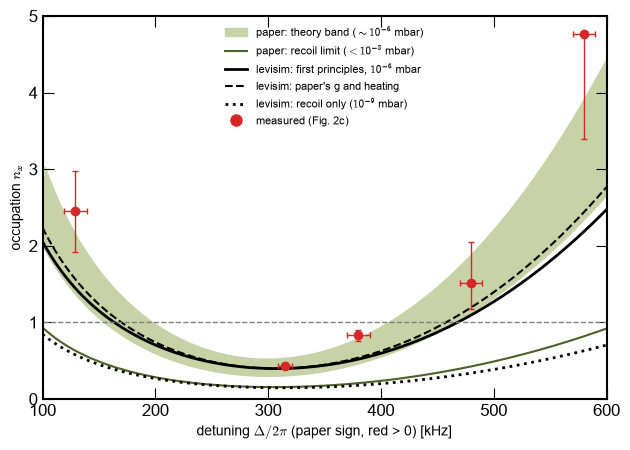

In [ ]:
fig, ax = plt.subplots(figsize=(6.4, 4.6))
ax.fill_between(grid, band_lo, band_hi, color='#c7d2a7', label=r'paper: theory band ($\sim 10^{-6}$ mbar)')
ax.plot(grid, paper_recoil, color='#4e602b', lw=1.5, label=r'paper: recoil limit ($< 10^{-8}$ mbar)')
ax.plot(Δs, n_first_principles, 'k-', lw=2, label=r'levisim: first principles, $10^{-6}$ mbar')
ax.plot(Δs, n_paper_rates, 'k--', lw=1.5, label='levisim: paper\'s g and heating')
ax.plot(Δs, n_recoil_only, 'k:', lw=2, label=r'levisim: recoil only ($10^{-9}$ mbar)')
for p in fig2c['points']:
    ax.errorbar(p['Δ_kHz'], p['n'], yerr=[[p['n'] - p['n_lo']], [p['n_hi'] - p['n']]],
                xerr=[[p['Δ_kHz'] - p['Δ_lo']], [p['Δ_hi'] - p['Δ_kHz']]],
                fmt='o', color='C3', ms=6, capsize=2, zorder=5)
ax.errorbar([], [], fmt='o', color='C3', label='measured (Fig. 2c)')
ax.axhline(1, color='grey', lw=1, ls='--')
ax.set_xlim(Δs[0], Δs[-1])
ax.set_ylim(0, 5)
ax.set_xlabel(r'detuning $\Delta/2\pi$ (paper sign, red > 0) [kHz]')
ax.set_ylabel(r'occupation $n_x$')
ax.legend(fontsize=8, loc='upper center', frameon=False)
fig.tight_layout()

## Heterodyne spectra and sideband thermometry (Figs. 2a, 2b and Eqs. S2, S3)

The paper extracts $n_x$ from the ratio of the anti-Stokes and Stokes sidebands of the heterodyne
spectrum, corrected for the cavity envelope (Eq. S2):

$$\frac{a_\text{AS}}{a_\text{S}} = \frac{n_x}{n_x + 1}\,\frac{(\kappa/2)^2 + (\Delta + \Omega_x)^2}{(\kappa/2)^2 + (\Delta - \Omega_x)^2}.$$

(The inline expression after Eq. S3 of the arXiv version has the two cavity factors the other way
round; Eq. S2 is the one consistent with the cavity enhancing the anti-Stokes sideband.)
levisim's `heterodyne_spectrum` is $\langle a_\text{out} a_\text{out}^\dagger\rangle$ in shot-noise
units, so $S_\text{het} - 1$ is the normally ordered spectrum with the anti-Stokes sideband at
$+\Omega$. We apply the paper's two estimators to it - a joint fit of two equal-width Lorentzians
(Eq. S3) and the ratio of band powers integrated over $\pm(250\text{-}300)$ kHz, both corrected
with the cavity factor at the fitted (spring-shifted) frequency - and compare
them with the true occupation. levisim assumes unit detection efficiency, so absolute peak heights
are larger than in the measured spectra; only ratios are compared.

In [ ]:
def lorentzian(ω, a, ω0, γ):
    return a * (γ/2) / ((ω - ω0)**2 + (γ/2)**2)


def sideband_thermometry(mtrap_, Δ_paper, Ω0=Ω_MEASURED['x'], half_window=100*kHz):
    ω = mtrap_.ω_range
    S = mtrap_.heterodyne_spectrum(LAM) - 1
    sel = np.abs(np.abs(ω) - Ω0) < half_window

    def model(w, a_S, a_AS, Ωm, γ):
        return lorentzian(w, a_S, -Ωm, γ) + lorentzian(w, a_AS, +Ωm, γ)

    p0 = [S[sel].max()*10*kHz, S[sel].max()*10*kHz, Ω0, 20*kHz]
    (a_S, a_AS, Ωm, γ), _ = curve_fit(model, ω[sel], S[sel], p0=p0, maxfev=20000)

    def cavity_ratio(Ω):
        return ((κ_MEASURED/2)**2 + (Δ_paper + Ω)**2) / ((κ_MEASURED/2)**2 + (Δ_paper - Ω)**2)

    R_fit = a_AS / a_S
    band_AS = (ω > 250*kHz) & (ω < 300*kHz)
    band_S = (ω < -250*kHz) & (ω > -300*kHz)
    R_area = np.trapezoid(S[band_AS], ω[band_AS]) / np.trapezoid(S[band_S], ω[band_S])
    return dict(
        n_fit=R_fit / (cavity_ratio(Ωm) - R_fit),
        n_area=R_area / (cavity_ratio(Ωm) - R_area),
        Ω_fit=Ωm, γ_fit=γ, ω=ω, S=S,
    )


ω_grid = np.concatenate([np.arange(-450, -150, 0.25), np.arange(150, 450, 0.25)]) * kHz
spectra = {}
print(f'{"Δ/2π [kHz]":>10s} {"n_true":>8s} {"n_fit (S3)":>11s} {"n_area":>8s} {"Ω_fit/2π":>9s} {"γ_fit/2π":>9s} {"normal mode/2π, width/2π":>26s}')
for Δ_paper in (315*kHz, 380*kHz, 580*kHz):
    m = delic_multitrap(Δ_paper, axes=1, ω_range=ω_grid)
    th = sideband_thermometry(m, Δ_paper)
    f, w = mechanical_eigenfrequencies(m)
    spectra[Δ_paper] = th
    print(f'{Δ_paper/kHz:10.0f} {occupations(m)["x1"]:8.3f} {th["n_fit"]:11.3f} {th["n_area"]:8.3f}'
          f' {th["Ω_fit"]/kHz:9.1f} {th["γ_fit"]/kHz:9.1f} {f[0]/kHz:15.1f}, {w[0]/kHz:.1f} kHz')
m_check = delic_multitrap(380*kHz, axes=1, ω_range=np.linspace(-400, 400, 801)*kHz)
S_levisim = m_check.heterodyne_spectrum(LAM)
print(f'\npaper_tools.heterodyne vs MultiTrap.heterodyne_spectrum: max relative difference '
      f'{np.max(np.abs(heterodyne(m_check, m_check.ω_range)/S_levisim - 1)):.1e}')

Δ/2π [kHz]   n_true  n_fit (S3)   n_area  Ω_fit/2π  γ_fit/2π   normal mode/2π, width/2π
       315    0.398       0.434    0.261     265.6     232.0           233.0, 88.9 kHz
       380    0.519       0.519    0.546     260.0      61.1           253.8, 49.3 kHz
       580    2.186       2.273    2.249     277.4      11.0           277.2, 11.0 kHz

paper_tools.heterodyne vs MultiTrap.heterodyne_spectrum: max relative difference 6.7e-16


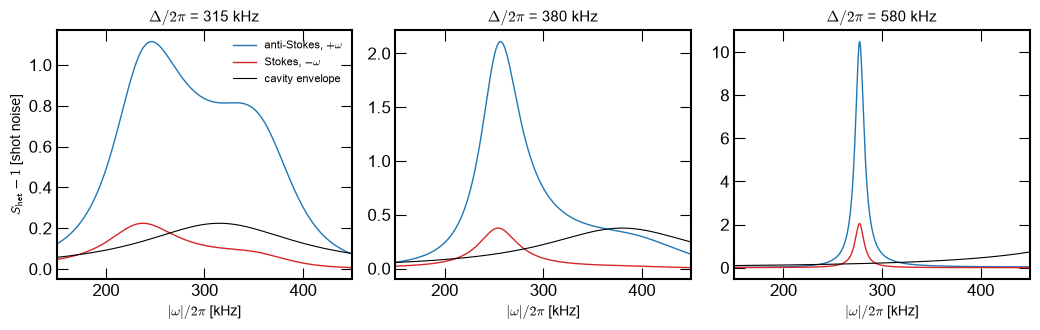

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.4), sharey=False)
for ax, (Δ_paper, th) in zip(axes, spectra.items()):
    ω, S = th['ω'], th['S']
    pos, neg = ω > 0, ω < 0
    T_cav = (κ_MEASURED/2)**2 / ((κ_MEASURED/2)**2 + (Δ_paper - ω[pos])**2)
    ax.plot(ω[pos]/kHz, S[pos], color='C0', label='anti-Stokes, $+\\omega$')
    ax.plot(-ω[neg]/kHz, S[neg], color='C3', label='Stokes, $-\\omega$')
    ax.plot(ω[pos]/kHz, T_cav * S[neg][::-1].max(), 'k-', lw=0.8, label='cavity envelope')
    ax.set_xlim(150, 450)
    ax.set_title(f'$\\Delta/2\\pi$ = {Δ_paper/kHz:.0f} kHz', fontsize=11)
    ax.set_xlabel(r'$|\omega|/2\pi$ [kHz]')
axes[0].set_ylabel(r'$S_\mathrm{het} - 1$ [shot noise]')
axes[0].legend(fontsize=8, frameon=False)
fig.tight_layout()

## Summary

All numbers below are printed by the cells above.

**Agreement.**

- From the stated tweezer power, waists, particle size and cavity geometry, levisim gives a cavity
  drive $\omega_d/2\pi = 4.33 \times 10^9$ Hz (paper: "≈ 4 × 10⁹ Hz"), a zero-point fluctuation of
  3.12 pm (paper: 3.1 pm) and an $x$ recoil heating rate of 5.6 kHz (paper: 6 kHz calculated,
  4.3 ± 1 kHz inferred).
- With these first-principles rates and levisim's gas damping at $10^{-6}$ mbar, the minimum is
  $n_x = 0.396$ at 308 kHz and $n_x = 0.397$ at 315 kHz, against the measured $0.43 \pm 0.03$
  (about 1σ below), inside the paper's own theory band (0.31-0.54 at 315 kHz). Imposing the
  paper's inferred $g_x$ and heating rates instead gives 0.399. Keeping $y$ and $z$ in the model
  changes nothing (0.398), as they are uncoupled at $\theta = 90°$ at the node.
- The paper's band edges at 315 kHz correspond, in levisim, to pressures of
  $6.4 \times 10^{-7}$ to $1.6 \times 10^{-6}$ mbar, i.e. the "∼10⁻⁶ mbar" of the paper.
- The recoil-limited curve has its minimum 0.145 at 312 kHz, against 0.154 at 304 kHz for the
  paper's "<10⁻⁸ mbar" curve (6 % apart).
- Sideband thermometry on levisim's own spectra recovers the true occupation to within 5 % at 380
  and 580 kHz with both estimators.

**Discrepancies, and where they come from.**

- levisim's $g_x/2\pi$ = 79.7 kHz is 12 % above the paper's inferred 71 kHz, and its gas heating
  at exactly $10^{-6}$ mbar (18.7 kHz) is 16 % above the measured 16.1 ± 1.2 kHz. Both are within
  the parameter uncertainties (the diameter ±4 nm enters $g$ as $r^{3/2}$; the pressure is "∼10⁻⁶ mbar").
- Away from the optimum the measured occupations lie above both levisim and the paper's band:
  at 380 kHz 0.83 ± 0.07 against 0.52-0.54 (band 0.47-0.80), at 580 kHz 4.8 against 2.2-2.4
  (band 2.35-3.92). The paper's own model shows the same tension, so it is not a levisim
  artefact; a heating or thermometry effect that grows with detuning would explain it, and the
  paper does not identify one.
- At the optimum $g_x/\kappa = 0.41$, so the $x$ sideband is hybridised with the cavity (levisim's
  normal mode sits at 233 kHz with an 89 kHz linewidth, against the bare 305 kHz). The Lorentzian
  fit then overestimates $n_x$ by 9 % and the band-power ratio underestimates it by 34 %. The
  paper's use of three estimators, and its worst case of 0.91, are consistent with a systematic
  uncertainty of this size at the optimum.

**Not modelled.** Laser phase and intensity noise (bounded by the paper), imperfect polarisation
alignment (which makes $y$ visible in the measured spectra), and any static coherent-scattering
frequency shift (zero at the node). Photon recoil is levisim's own (`MultiTrap(photon_recoil=True)`);
only the "paper's rates" curve imposes a heating rate from outside, the paper's total, on a
toy-parameter system with `paper_tools.add_heating`.

In [ ]:
print(f'notebook runtime: {time.time() - T_START:.1f} s')

notebook runtime: 0.9 s
